<h1 align = "center">
Rwanda Maize-Urea Trial
</h1>

<h2 align = "center">
Yield Prediction Model
</h2> 

### Objective

In this notebook what we want to achieve is first test whether the information we already have can predict maize yield on fields that our model has not seen yet. 

#### Prediction Task

For the primary prediction exercise, we want to use a **pre-planting decision scenario** where an extension officer knows the field's location and characteristics, the season, and the planned fertilizer treatment, but does not yet know germination, silking, or harvest outcomes.

- In this case we don't expect to use `germination_rate`, `silking_date`, `R3_date` or any other informatin that we expect to only be available after planting  in our first model. 

    - We way want to use those variables in a later mid-season forecasting model.

### Imports and Setup

We want to first prepare the prediction dataset.

- We'll load our cleaned field and plot datasets accordingly

In [1]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path

# Defining path to folder
data_path = Path(r"../01_Data/processed")

def load_csv (filename):
    return pd.read_csv(data_path/filename)

field_clean = load_csv("field_clean.csv")
plot_clean = load_csv("plot_clean.csv")

In [3]:
# Join plot outcomes and treatment information to field characteristics
field_features = [
    "block_id", "season", "meg_env", "lat", "long", "alt",
    "landscape_pos", "slope_pos", "soil_color", "rockness",
    "soil_depth", "slope", "cult_land"
]

prediction_df = plot_clean.merge(
    field_clean[field_features],
    on=["block_id", "season"],
    how="left",
    validate="many_to_one"
)

print("Prediction dataset:", prediction_df.shape)
print("Missing yield:", prediction_df["yield_tha"].isna().sum())
print("Missing mega-environment:", prediction_df["meg_env"].isna().sum())

Prediction dataset: (1598, 54)
Missing yield: 0
Missing mega-environment: 5


#### Model Comparison

We want to compare the baseline, linear model and a random forest

- **Baseline:** preditc the training-set average yield

- **Linear regression:** captures relatively simple relationships between predictors and yield

- **Random Forest:** can capture non-linear relationships and interactions. But it can also overfit with limited data.

We want to use five-fold grouped cross-validation: should keep all plots from the same block_id together. 

- This should help prevent the model from being evaluated on other plots from a field it has already seen.

#### Farmer-facing extension advisory

We are interested in an extension advisory tool that does not simply select whichever treatment has the highest observed average. Instead we want to rely on it if it recommends treatments based on estimated performance, uncertainty and practical constraints. 

Our four strategies are:

|Treatment	|Urea rate	|Application schedule|
|----|----|----|
|Low rate	|50 kg/ha	|All at V6|
|Full rate A	|100 kg/ha	|Half at planting, half at V6|
|Full rate B	|100 kg/ha	|All at V6|
|Full rate C	|100 kg/ha	|Half at V6, half at V10|

From our primary mixed-effects model, the evidence indicates to us that:

- Applying 100 kg/ha entirely at V6 was associated with about 0.546 t/ha higher yield than 50 kg/ha at V6.

- Splitting 100 kg/ha between V6 and V10 was associated with about 0.500 t/ha higher yield.

- The difference between those two full-rate strategies was not statistically significant.

- Splitting 100 kg/ha between planting and V6 did not significantly outperform the 50 kg/ha reference in the primary model.

- The treatment-by-mega-environment interaction was not statistically significant (\(p \approx 0.424\)).

Consequently, the existing evidence does not justify claiming that different mega-environments require different fertilizer schedules. We can still report environment-specific estimates, but the evidence for tailoring recommendations geographically is currently limited.

**The decision rule, therefore, should be:**

The tool should eventually take a farmer's field context and practical constraints, then present:

1. Estimated yield for each treatment.

2. Uncertainty around each estimate.

3. Expected yield difference relative to the low-rate treatment.

4. Additional Urea requirement and application workload.

5. Expected net economic benefit, once local input and maize prices are supplied.

6. A recommendation with an explanation and an uncertainty warning where evidence is insufficient.

For example, the all-at-V6 strategy may be an attractive provisional yield-based option because it has a positive estimated yield difference and is operationally simple. But we should not call it the economically optimal recommendation until we account for fertilizer costs, labour, maize prices, and the risk associated with the additional fertilizer.

A key principle: the predictive model will support yield forecasting, while the treatment model will support the comparison of fertilizer strategies. We should not use predictive accuracy as a substitute for treatment-effect evidence.

In [4]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Only use records with an outcome and field identifier
model_df = prediction_df.dropna(
    subset=["yield_tha", "block_id"]
).copy()

categorical_features = [
    "urea_rate_timing",
    "season",
    "meg_env",
    "landscape_pos",
    "slope_pos",
    "soil_color",
    "rockness"
]

numeric_features = [
    "lat", "long", "alt", "soil_depth", "slope", "cult_land"
]

In [5]:
# Convert numeric predictors to numeric types
for col in numeric_features:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

In [6]:
# Use only columns available for this prediction scenario
feature_columns = categorical_features + numeric_features

X = model_df[feature_columns]
y = model_df["yield_tha"]
groups = model_df["block_id"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge regression": Ridge(alpha=1.0),
    "Random forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

cv = GroupKFold(n_splits=5)

results = []
prediction_records = []

In [7]:

for model_name, estimator in models.items():

    fold_predictions = np.full(len(model_df), np.nan)

    for train_idx, test_idx in cv.split(X, y, groups):

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", estimator)
        ])

        pipeline.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        fold_predictions[test_idx] = pipeline.predict(
            X.iloc[test_idx]
        )

    mae = mean_absolute_error(y, fold_predictions)
    rmse = np.sqrt(mean_squared_error(y, fold_predictions))
    r2 = r2_score(y, fold_predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    prediction_records.append(
        pd.DataFrame({
            "actual_yield": y.to_numpy(),
            "predicted_yield": fold_predictions,
            "model": model_name,
            "block_id": groups.to_numpy()
        })
    )

model_results = pd.DataFrame(results).sort_values("RMSE")
print(model_results.round(3))

              Model    MAE   RMSE     R2
2     Random forest  1.285  1.941  0.206
1  Ridge regression  1.298  1.965  0.186
0     Mean baseline  1.532  2.182 -0.004


**So what do these results mean?**

**A. Random Forest performs best, but only narrowly.**

- Compared with the mean baseline, Random Forest reduces MAE by approximately 16.1% and RMSE by 11.0%. Ridge Regression also improves on the baseline, with reductions of approximately 15.3% and 9.9%, respectively.

- However, Random Forest's MAE is only 0.013 t/ha lower than Ridge Regression's. That is a very small difference, so we don't want to conclude that Random Forest is definitively superior.

**B. Prediction errors remain substantial.**

- The Random Forest MAE of 1.285 t/ha means that its predictions differ from observed yields by an average absolute amount of approximately 1.29 tonnes per hectare across the cross-validation predictions.

- Its RMSE of 1.941 t/ha is higher because RMSE penalizes large errors more heavily. This suggests that some predictions may have relatively large errors, although we need to inspect the residuals to understand their frequency and causes.

**C. The model explains only a limited proportion of yield variation.**

- An R² of 0.206 means that Random Forest explains about 20.6% of the variation in yield relative to the overall mean benchmark under this cross-validation evaluation.

- This is not necessarily a failure; Maize yield depends on many factors that our dataset does not fully capture, including rainfall, temperature, pest pressure, and other soil properties. But we don't want to describe this model as highly accurate or use it to make precise yield guarantees.

- The negative baseline R² of -0.004 is also informative: predicting the overall mean performs slightly worse than using the mean of the held-out observations in the pooled cross-validation calculation.

#### Examining the Model

We want to examine where the model makes mistakes: before tuning them or adding complexity, we want to undertsand their prediction errors. 

We are interested in answering:

- Does the model systematically overpredict or underpredict yield?

- Are the largest errors concentrated among unusually high or low yields?

- Does Random Forest genuinely perform better across the yield range, or does its overall score conceal weaknesses?

We'll begin by preparing the cross-validation predictions

Our earlier model loop stored the out-of-fold predictions in `prediction_records`. Each prediction was generated by a model that had not been trained on that observation's field group.

In [8]:
# Combine the cross-validation predictions
all_predictions = pd.concat(
    prediction_records,
    ignore_index=True
)

# Calculate prediction errors
all_predictions["error"] = (
    all_predictions["predicted_yield"]
    - all_predictions["actual_yield"]
)

all_predictions["absolute_error"] = (
    all_predictions["error"].abs()
)

all_predictions["squared_error"] = (
    all_predictions["error"] ** 2
)

# Inspect Random Forest predictions
rf_predictions = all_predictions.loc[
    all_predictions["model"] == "Random forest"
].copy()



What are we looking for?

We want to check whether the model overpredicts or underpredicts yield.

- a positive error means the model overpredicted yield; 

- a negative error means it underpredicted yield.

In [9]:

print(rf_predictions.head())

print(
    rf_predictions["absolute_error"].describe().round(3)
)

      actual_yield  predicted_yield          model  \
3196          4.52         5.119935  Random forest   
3197          4.20         5.049298  Random forest   
3198          3.49         5.573040  Random forest   
3199          3.58         5.302804  Random forest   
3200          4.59         4.654637  Random forest   

                                  block_id     error  absolute_error  \
3196  adfa31ad-95bf-453d-94f1-d163a97756ee  0.599935        0.599935   
3197  adfa31ad-95bf-453d-94f1-d163a97756ee  0.849298        0.849298   
3198  adfa31ad-95bf-453d-94f1-d163a97756ee  2.083040        2.083040   
3199  adfa31ad-95bf-453d-94f1-d163a97756ee  1.722804        1.722804   
3200  d8807f25-e675-49ae-87a3-d228eca23c72  0.064637        0.064637   

      squared_error  
3196       0.359922  
3197       0.721307  
3198       4.339056  
3199       2.968053  
3200       0.004178  
count    1598.000
mean        1.285
std         1.455
min         0.000
25%         0.493
50%         1.054
75

### Observed vs Predicted Yield Plot

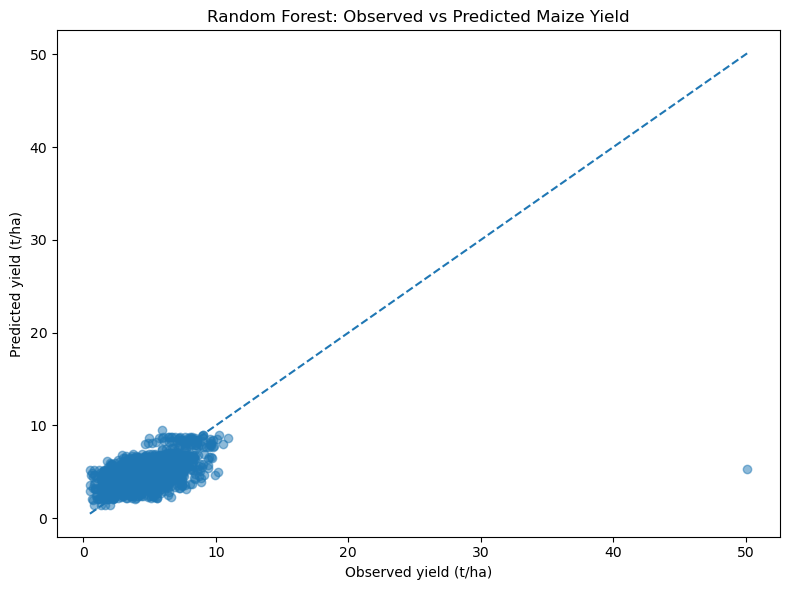

In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    rf_predictions["actual_yield"],
    rf_predictions["predicted_yield"],
    alpha=0.5
)

# Reference line for perfect predictions
lower = min(
    rf_predictions["actual_yield"].min(),
    rf_predictions["predicted_yield"].min()
)

upper = max(
    rf_predictions["actual_yield"].max(),
    rf_predictions["predicted_yield"].max()
)

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

ax.set_xlabel("Observed yield (t/ha)")
ax.set_ylabel("Predicted yield (t/ha)")
ax.set_title("Random Forest: Observed vs Predicted Maize Yield")

plt.tight_layout()
plt.show()

We want to note that points close to the diagonal represent accurate predictions. 

- If the points cluster around the middle while the diagonal's extremes are poorly represented, the model may be struggling to predict very low and very high yields.

- We have to also acknowledge that the previously identified observation of 50.1 t/ha could have a substantial influence on these diagnostics.

### Examining Residuals

We want to look for systematic patterns, such as positive errors at one end of the predicted-yield range and negative errors at the other. 

Such a pattern suggest that the model is not adequately capturing the relationship between its predictors and yield.

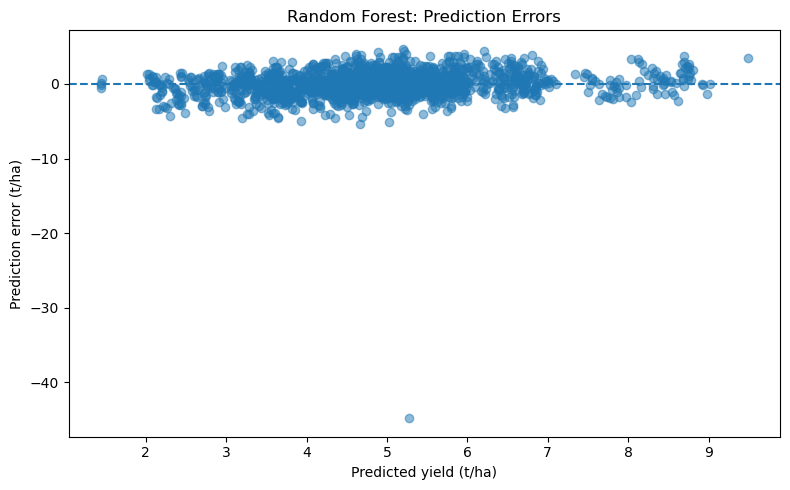

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    rf_predictions["predicted_yield"],
    rf_predictions["error"],
    alpha=0.5
)

ax.axhline(0, linestyle="--")

ax.set_xlabel("Predicted yield (t/ha)")
ax.set_ylabel("Prediction error (t/ha)")
ax.set_title("Random Forest: Prediction Errors")

plt.tight_layout()
plt.show()

#### Testing Sensitivity to Extreme Yield Observation

We want to also determine whether the unusually high yield of 50.1 t/ha is distorting the prediction results.

We aren't deleting it from the project dataset yet, but instead, we want to repeat the cross-validation exercise without that observation and compare the performance metrics.

This is a sensitivity analysis, not a claim that the observation is invalid.

In [14]:
# Exclude the extreme observation for sensitivity analysis only
model_df_sensitivity = model_df.loc[
    model_df["yield_tha"] != 50.1
].copy()

print("Original sample size:", len(model_df))
print("Sensitivity sample size:", len(model_df_sensitivity))

Original sample size: 1598
Sensitivity sample size: 1597
